In [1]:
import pandas as pd

df = pd.read_csv('/content/TWITTER DATA -SAMPLE  - Sheet1.csv')

df.head()

,userId,followersCount,friendsCount,twitt,topic,id,retwit,retwitCount
0,1.0,129,116,Sports Photos! #MLB #Cubs at #Brewers - by @Lf...,sports,40886,True,1
1,8.0,8,111,[ARTICLE] Kang Daniel thumbs up to Yoon Sung B...,sports,40887,True,14
2,3.0,1243,115,Jets' Wheeler on 5-year extension: 'I couldn't...,sports,40888,True,1
3,4.0,682,1013,just wanted to say thank you to the three offi...,sports,40889,True,7
4,5.0,1,14,They started with FAR more Capitol. That is EX...,sports,40890,False,0


In [2]:
df.shape

(351, 8)

In [3]:
df.columns

Index(['userId', 'followersCount', 'friendsCount', 'twitt', 'topic', 'id',
       'retwit', 'retwitCount'],
      dtype='object')

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
print("Unique Topics:")
print(df['topic'].unique())

print("\nNumber of Classes:")
print(df['topic'].nunique())

print("\nClass Distribution:")
print(df['topic'].value_counts())

Unique Topics:
['sports' 'flood' 'politics' 'health' 'terrorism']

Number of Classes:
5

Class Distribution:
topic
sports       109
health       102
flood         63
terrorism     46
politics      31
Name: count, dtype: int64


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Missing Values:
userId            1
followersCount    0
friendsCount      0
twitt             0
topic             0
id                0
retwit            0
retwitCount       0
dtype: int64

Data Types:
userId            float64
followersCount      int64
friendsCount        int64
twitt              object
topic              object
id                  int64
retwit               bool
retwitCount         int64
dtype: object


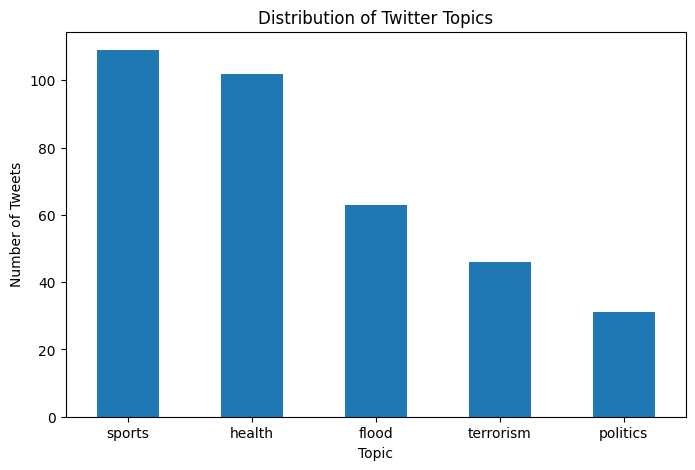

In [6]:
import matplotlib.pyplot as plt

topic_counts = df['topic'].value_counts()

plt.figure(figsize=(8, 5))
topic_counts.plot(kind='bar')

plt.title('Distribution of Twitter Topics')
plt.xlabel('Topic')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=0)
plt.show()

In [7]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate tweets:", df['twitt'].duplicated().sum())

Duplicate rows: 0
Duplicate tweets: 50


In [8]:
df['tweet_length'] = df['twitt'].astype(str).apply(len)

print(df['tweet_length'].describe())

count    351.000000
mean     147.014245
std       50.393450
min       43.000000
25%      129.000000
50%      142.000000
75%      146.000000
max      304.000000
Name: tweet_length, dtype: float64


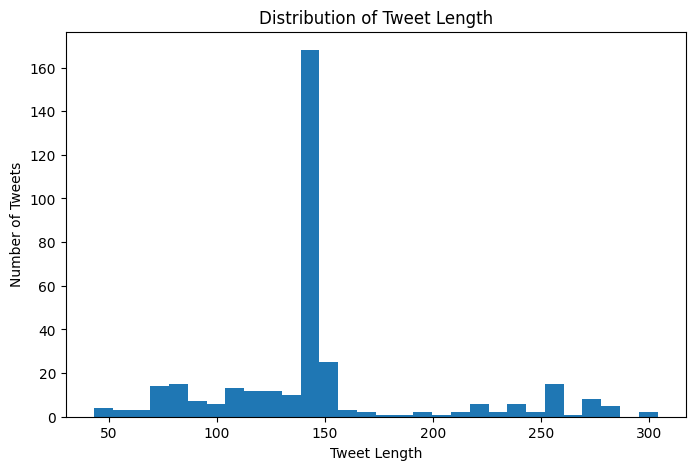

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df['tweet_length'], bins=30)

plt.title('Distribution of Tweet Length')
plt.xlabel('Tweet Length')
plt.ylabel('Number of Tweets')

plt.show()

In [10]:
for topic in df['topic'].unique():
    print("\n==============================")
    print("TOPIC:", topic.upper())
    print("==============================")

    display(df[df['topic'] == topic][['twitt', 'topic']].head(3))


TOPIC: SPORTS


,twitt,topic
0,Sports Photos! #MLB #Cubs at #Brewers - by @Lf...,sports
1,[ARTICLE] Kang Daniel thumbs up to Yoon Sung B...,sports
2,Jets' Wheeler on 5-year extension: 'I couldn't...,sports



TOPIC: FLOOD


,twitt,topic
109,RT @kiloleelo: blessed too see 17. happy birth...,flood
110,"Flood Advisory for portions of Coke, Nolan, an...",flood
111,You can't turn off the flood when the dam brea...,flood



TOPIC: POLITICS


,twitt,topic
172,RT @AGerberBaby: The #fakenews ?@nytimes shoul...,politics
173,RT @RamCNN: Woodward book prompts West Wing wi...,politics
174,RT @GlennThrush: The visuals yesterday were es...,politics



TOPIC: HEALTH


,twitt,topic
203,"RT @KamalaHarris: Make no mistake, the most cr...",health
204,Comments in threads on here are absolutely tox...,health
205,RT @jbouie: The narrative that Democrats are f...,health



TOPIC: TERRORISM


,twitt,topic
305,RT @Trey_VonDinkis: #LeftistSedition #Illegals...,terrorism
306,RT @USAloveGOD: #Flashback to Terrorism\n #Sep...,terrorism
307,RT @KrisParonto: Shadow Ban me all you want @T...,terrorism


In [11]:
# Create a copy of the dataset
data = df.copy()

# Remove the row with missing userId
data = data.dropna(subset=['userId'])

# Remove duplicate tweet texts
data = data.drop_duplicates(subset=['twitt'])

# Reset index
data = data.reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after cleaning:", len(data))
print("Duplicate tweets remaining:", data['twitt'].duplicated().sum())

Original rows: 351
Rows after cleaning: 300
Duplicate tweets remaining: 0


In [12]:
print(data['topic'].value_counts())

topic
sports       93
health       87
flood        50
terrorism    40
politics     30
Name: count, dtype: int64


In [13]:
data.head()

,userId,followersCount,friendsCount,twitt,topic,id,retwit,retwitCount,tweet_length
0,1.0,129,116,Sports Photos! #MLB #Cubs at #Brewers - by @Lf...,sports,40886,True,1,77
1,8.0,8,111,[ARTICLE] Kang Daniel thumbs up to Yoon Sung B...,sports,40887,True,14,127
2,3.0,1243,115,Jets' Wheeler on 5-year extension: 'I couldn't...,sports,40888,True,1,116
3,4.0,682,1013,just wanted to say thank you to the three offi...,sports,40889,True,7,124
4,5.0,1,14,They started with FAR more Capitol. That is EX...,sports,40890,False,0,112


In [14]:
import re

def clean_tweet(text):
    text = str(text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove @mentions
    text = re.sub(r'@\w+', '', text)

    # Remove "RT"
    text = re.sub(r'\brt\b', '', text)

    # Keep hashtag words but remove # symbol
    text = re.sub(r'#', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

data['clean_tweet'] = data['twitt'].apply(clean_tweet)

data[['twitt', 'clean_tweet', 'topic']].head(10)

,twitt,clean_tweet,topic
0,Sports Photos! #MLB #Cubs at #Brewers - by @Lf...,sports photos mlb cubs at brewers by,sports
1,[ARTICLE] Kang Daniel thumbs up to Yoon Sung B...,article kang daniel thumbs up to yoon sung bin...,sports
2,Jets' Wheeler on 5-year extension: 'I couldn't...,jets wheeler on year extension i couldn t see ...,sports
3,just wanted to say thank you to the three offi...,just wanted to say thank you to the three offi...,sports
4,They started with FAR more Capitol. That is EX...,they started with far more capitol that is ext...,sports
5,": Long before the Nike ad, Kaepernick7 was a 4...",long before the nike ad kaepernick was a ers s...,sports
6,RT FirstpostSports: .RafaelNadal wins it!\n \n...,firstpostsports rafaelnadal wins it it s been ...,sports
7,"Local results: Volleyball, golf https://t.co/k...",local results volleyball golf,sports
8,women think cramps and childbirth hurt. excuse...,women think cramps and childbirth hurt excuse ...,sports
9,RT Blac_Maleficent: midonoqayi zazashongwe00 I...,blac maleficent midonoqayi zazashongwe it was ...,sports


In [15]:
print(data[['twitt', 'clean_tweet', 'topic']].head(10).to_string())

                                                                                                                                                                                                                                                          twitt                                                                                                                                                                                                                         clean_tweet   topic
0                                                                                                                                                                                 Sports Photos! #MLB #Cubs at #Brewers - by @Lfiles37: https://t.co/ZGGtAaKekm                                                                                                                                                                                                sports photos mlb cubs at brewers by  sports
1               

In [16]:
from sklearn.model_selection import train_test_split

X = data['clean_tweet']
y = data['topic']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 240
Testing samples: 60


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 1)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (240, 1657)
Testing TF-IDF shape: (60, 1657)


In [18]:
tfidf.fit_transform(X_train)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2518 stored elements and shape (240, 1657)>

In [19]:
tfidf.transform(X_test)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 277 stored elements and shape (60, 1657)>

In [20]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()

nb.fit(X_train_tfidf, y_train)

y_pred = nb.predict(X_test_tfidf)

print("Predictions completed!")

Predictions completed!


In [21]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Naive Bayes Accuracy:", accuracy)
print("Naive Bayes Accuracy (%):", accuracy * 100)

Naive Bayes Accuracy: 0.6833333333333333
Naive Bayes Accuracy (%): 68.33333333333333


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("Naive Bayes Performance")
print("-----------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Naive Bayes Performance
-----------------------
Accuracy  : 0.6833
Precision : 0.6941
Recall    : 0.6833
F1-Score  : 0.6092

Classification Report:
              precision    recall  f1-score   support

       flood       1.00      0.50      0.67        10
      health       0.73      0.94      0.82        17
    politics       0.00      0.00      0.00         6
      sports       0.59      1.00      0.75        19
   terrorism       1.00      0.12      0.22         8

    accuracy                           0.68        60
   macro avg       0.66      0.51      0.49        60
weighted avg       0.69      0.68      0.61        60



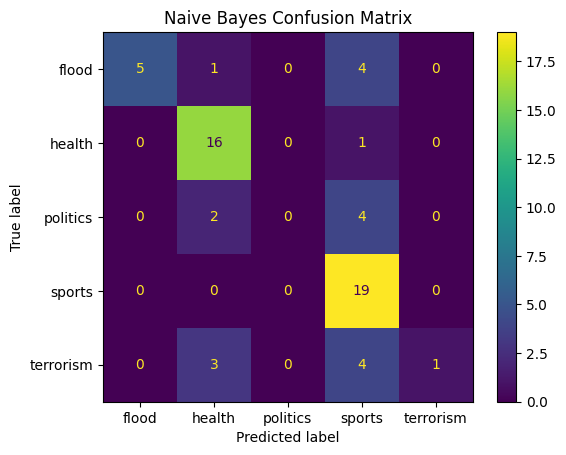

In [23]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nb.classes_
)

disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# -------------------------------
# 1. Naive Bayes
# -------------------------------
nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train)

nb_pred = nb.predict(X_test_tfidf)


# -------------------------------
# 2. Logistic Regression
# -------------------------------
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr.fit(X_train_tfidf, y_train)

lr_pred = lr.predict(X_test_tfidf)


# -------------------------------
# 3. Support Vector Machine
# -------------------------------
svm = LinearSVC(
    random_state=42
)

svm.fit(X_train_tfidf, y_train)

svm_pred = svm.predict(X_test_tfidf)


# -------------------------------
# Calculate Metrics
# -------------------------------

models = {
    "Naive Bayes": nb_pred,
    "Logistic Regression": lr_pred,
    "SVM": svm_pred
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test,
        predictions,
        average='weighted',
        zero_division=0
    )
    recall = recall_score(
        y_test,
        predictions,
        average='weighted',
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        predictions,
        average='weighted',
        zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

results

[['Naive Bayes',
  0.6833333333333333,
  0.6940814393939393,
  0.6833333333333333,
  0.6091670856376739],
 ['Logistic Regression', 0.8, 0.7495061728395063, 0.8, 0.7534228736745898],
 ['SVM', 0.85, 0.8569298245614035, 0.85, 0.8467236467236466]]

In [25]:
import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=[
        "Algorithm",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ]
)

results_df

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.683333,0.694081,0.683333,0.609167
1,Logistic Regression,0.800000,0.749506,0.800000,0.753423
2,SVM,0.850000,0.856930,0.850000,0.846724


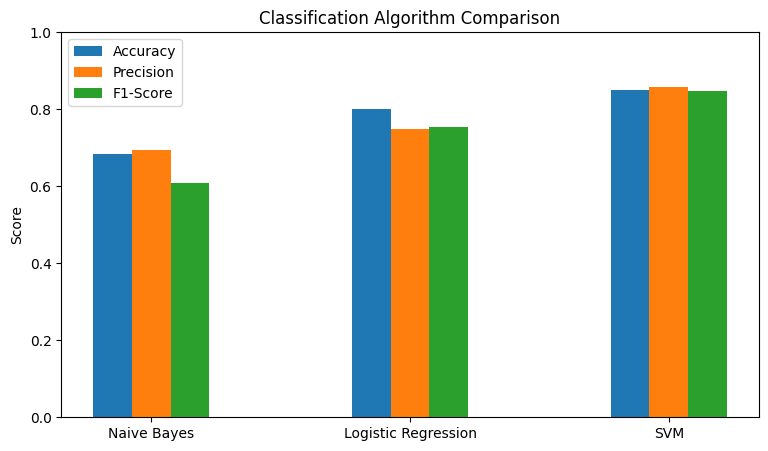

In [26]:
plt.figure(figsize=(9, 5))

x = range(len(results_df))

plt.bar(
    [i - 0.15 for i in x],
    results_df["Accuracy"],
    width=0.15,
    label="Accuracy"
)

plt.bar(
    [i for i in x],
    results_df["Precision"],
    width=0.15,
    label="Precision"
)

plt.bar(
    [i + 0.15 for i in x],
    results_df["F1-Score"],
    width=0.15,
    label="F1-Score"
)

plt.xticks(x, results_df["Algorithm"])
plt.ylabel("Score")
plt.title("Classification Algorithm Comparison")
plt.ylim(0, 1)
plt.legend()

plt.show()

In [27]:
# TF-IDF with Unigrams + Bigrams

tfidf_bigram = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    min_df=1
)

X_train_bigram = tfidf_bigram.fit_transform(X_train)
X_test_bigram = tfidf_bigram.transform(X_test)

print("Training shape:", X_train_bigram.shape)
print("Testing shape:", X_test_bigram.shape)

Training shape: (240, 3884)
Testing shape: (60, 3884)


In [28]:
svm_bigram = LinearSVC(random_state=42)

svm_bigram.fit(X_train_bigram, y_train)

svm_bigram_pred = svm_bigram.predict(X_test_bigram)

bigram_accuracy = accuracy_score(y_test, svm_bigram_pred)
bigram_precision = precision_score(
    y_test,
    svm_bigram_pred,
    average='weighted',
    zero_division=0
)
bigram_recall = recall_score(
    y_test,
    svm_bigram_pred,
    average='weighted',
    zero_division=0
)
bigram_f1 = f1_score(
    y_test,
    svm_bigram_pred,
    average='weighted',
    zero_division=0
)

print("SVM with Unigrams + Bigrams")
print("----------------------------")
print(f"Accuracy  : {bigram_accuracy:.4f}")
print(f"Precision : {bigram_precision:.4f}")
print(f"Recall    : {bigram_recall:.4f}")
print(f"F1-Score  : {bigram_f1:.4f}")

SVM with Unigrams + Bigrams
----------------------------
Accuracy  : 0.8500
Precision : 0.8569
Recall    : 0.8500
F1-Score  : 0.8467


In [29]:
import numpy as np
from scipy.sparse import csr_matrix, hstack
from sklearn.preprocessing import StandardScaler

# Get corresponding rows for train and test
train_data = data.loc[X_train.index].copy()
test_data = data.loc[X_test.index].copy()

# Select numerical Twitter features
numeric_features = [
    'followersCount',
    'friendsCount',
    'retwitCount'
]

# Convert retwit True/False to 0/1
train_data['retwit_numeric'] = train_data['retwit'].astype(int)
test_data['retwit_numeric'] = test_data['retwit'].astype(int)

numeric_features.append('retwit_numeric')

# Log transform count-based features
for col in ['followersCount', 'friendsCount', 'retwitCount']:
    train_data[col] = np.log1p(train_data[col])
    test_data[col] = np.log1p(test_data[col])

# Scale numerical features
scaler = StandardScaler()

X_train_numeric = scaler.fit_transform(
    train_data[numeric_features]
)

X_test_numeric = scaler.transform(
    test_data[numeric_features]
)

# Convert to sparse matrices
X_train_numeric = csr_matrix(X_train_numeric)
X_test_numeric = csr_matrix(X_test_numeric)

print("Numeric training shape:", X_train_numeric.shape)
print("Numeric testing shape:", X_test_numeric.shape)

Numeric training shape: (240, 4)
Numeric testing shape: (60, 4)


In [30]:
# Combine text TF-IDF features with Twitter numerical features

X_train_hybrid = hstack([
    X_train_tfidf,
    X_train_numeric
])

X_test_hybrid = hstack([
    X_test_tfidf,
    X_test_numeric
])

print("Hybrid training shape:", X_train_hybrid.shape)
print("Hybrid testing shape:", X_test_hybrid.shape)

Hybrid training shape: (240, 1661)
Hybrid testing shape: (60, 1661)


In [32]:
hybrid_svm = LinearSVC(random_state=42)

hybrid_svm.fit(X_train_hybrid, y_train)

hybrid_pred = hybrid_svm.predict(X_test_hybrid)

In [33]:
hybrid_accuracy = accuracy_score(y_test, hybrid_pred)

hybrid_precision = precision_score(
    y_test,
    hybrid_pred,
    average='weighted',
    zero_division=0
)

hybrid_recall = recall_score(
    y_test,
    hybrid_pred,
    average='weighted',
    zero_division=0
)

hybrid_f1 = f1_score(
    y_test,
    hybrid_pred,
    average='weighted',
    zero_division=0
)

print("Hybrid SVM - Text + Twitter Features")
print("--------------------------------------")
print(f"Accuracy  : {hybrid_accuracy:.4f}")
print(f"Precision : {hybrid_precision:.4f}")
print(f"Recall    : {hybrid_recall:.4f}")
print(f"F1-Score  : {hybrid_f1:.4f}")

Hybrid SVM - Text + Twitter Features
--------------------------------------
Accuracy  : 0.8500
Precision : 0.8530
Recall    : 0.8500
F1-Score  : 0.8440


In [34]:
# Class-Weighted SVM
weighted_svm = LinearSVC(
    class_weight='balanced',
    random_state=42
)

weighted_svm.fit(X_train_tfidf, y_train)

weighted_pred = weighted_svm.predict(X_test_tfidf)

In [35]:
weighted_accuracy = accuracy_score(y_test, weighted_pred)

weighted_precision = precision_score(
    y_test,
    weighted_pred,
    average='weighted',
    zero_division=0
)

weighted_recall = recall_score(
    y_test,
    weighted_pred,
    average='weighted',
    zero_division=0
)

weighted_f1 = f1_score(
    y_test,
    weighted_pred,
    average='weighted',
    zero_division=0
)

print("Class-Weighted SVM")
print("------------------")
print(f"Accuracy  : {weighted_accuracy:.4f}")
print(f"Precision : {weighted_precision:.4f}")
print(f"Recall    : {weighted_recall:.4f}")
print(f"F1-Score  : {weighted_f1:.4f}")

Class-Weighted SVM
------------------
Accuracy  : 0.8500
Precision : 0.8569
Recall    : 0.8500
F1-Score  : 0.8467


In [36]:
!pip install mlxtend -q

In [37]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import re

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [38]:
# Create word transactions

transactions = []

for tweet in data['clean_tweet']:
    words = tweet.split()

    # Remove very short words
    words = [word for word in words if len(word) >= 3]

    # Remove duplicate words within the same tweet
    words = list(set(words))

    transactions.append(words)

print("Number of transactions:", len(transactions))
print("Example transactions:")
for t in transactions[:5]:
    print(t)

Number of transactions: 300
Example transactions:
['mlb', 'cubs', 'sports', 'photos', 'brewers']
['daniel', 'man', 'manner', 'thumbs', 'expected', 'the', 'kang', 'yoon', 'sung', 'article', 'bin']
['myself', 'extension', 'year', 'wheeler', 'else', 'jets', 'anywhere', 'see', 'couldn']
['thank', 'nerf', 'party', 'officers', 'just', 'three', 'olds', 'say', 'the', 'norfolkpolice', 'who', 'our', 'gun', 'today', 'wanted', 'turned', 'you']
['with', 'capitol', 'rule', 'extremely', 'not', 'started', 'far', 'damn', 'more', 'they', 'across', 'the', 'that', 'sports', 'exception', 'rare']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [39]:
te = TransactionEncoder()

transaction_array = te.fit(transactions).transform(transactions)

transaction_df = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

print("Transaction matrix shape:", transaction_df.shape)

transaction_df.head()

Transaction matrix shape: (300, 2160)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,able,abortion,about,above,absolutely,abuse,academics,accepting,access,according,...,york,you,your,yourself,youth,yrs,zazashongwe,zero,zion,zone
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
frequent_itemsets_apriori = apriori(
    transaction_df,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets_apriori = frequent_itemsets_apriori.sort_values(
    by='support',
    ascending=False
)

print("Apriori frequent itemsets:")
display(frequent_itemsets_apriori.head(20))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori frequent itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
22,0.463333,(the)
1,0.303333,(and)
19,0.200000,(sports)
12,0.193333,(health)
8,0.176667,(for)
21,0.160000,(that)
36,0.153333,"(and, the)"
7,0.130000,(flood)
27,0.123333,(with)
28,0.123333,(you)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [41]:
frequent_itemsets_fpgrowth = fpgrowth(
    transaction_df,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets_fpgrowth = frequent_itemsets_fpgrowth.sort_values(
    by='support',
    ascending=False
)

print("FP-Growth frequent itemsets:")
display(frequent_itemsets_fpgrowth.head(20))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth frequent itemsets:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
1,0.463333,(the)
11,0.303333,(and)
0,0.200000,(sports)
28,0.193333,(health)
19,0.176667,(for)
6,0.160000,(that)
39,0.153333,"(and, the)"
27,0.130000,(flood)
7,0.123333,(with)
2,0.123333,(you)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [42]:
rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric='confidence',
    min_threshold=0.5
)

rules_apriori = rules_apriori.sort_values(
    by='lift',
    ascending=False
)

print("Top Apriori Association Rules:")
display(
    rules_apriori[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top Apriori Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
11,"(health, the)",(and),0.053333,0.551724,1.818871
13,(have),(and),0.050000,0.535714,1.766091
9,(from),(the),0.056667,0.739130,1.595246
12,(who),(the),0.053333,0.695652,1.501408
10,"(and, health)",(the),0.053333,0.666667,1.438849
5,(are),(the),0.073333,0.628571,1.356629
3,(that),(the),0.096667,0.604167,1.303957
4,(with),(the),0.073333,0.594595,1.283298
8,(all),(the),0.056667,0.586207,1.265195
6,(you),(the),0.066667,0.540541,1.166634


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [43]:
rules_fpgrowth = association_rules(
    frequent_itemsets_fpgrowth,
    metric='confidence',
    min_threshold=0.5
)

rules_fpgrowth = rules_fpgrowth.sort_values(
    by='lift',
    ascending=False
)

print("Top FP-Growth Association Rules:")
display(
    rules_fpgrowth[
        ['antecedents', 'consequents', 'support', 'confidence', 'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top FP-Growth Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
11,"(health, the)",(and),0.053333,0.551724,1.818871
13,(have),(and),0.050000,0.535714,1.766091
8,(from),(the),0.056667,0.739130,1.595246
12,(who),(the),0.053333,0.695652,1.501408
10,"(and, health)",(the),0.053333,0.666667,1.438849
4,(are),(the),0.073333,0.628571,1.356629
2,(that),(the),0.096667,0.604167,1.303957
5,(with),(the),0.073333,0.594595,1.283298
9,(all),(the),0.056667,0.586207,1.265195
6,(you),(the),0.066667,0.540541,1.166634


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [44]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

transactions_clean = []

for tweet in data['clean_tweet']:
    words = tweet.split()

    # Remove stopwords, very short words, and duplicate words
    words = [
        word for word in words
        if len(word) >= 3 and word not in stop_words
    ]

    words = list(set(words))

    # Keep transactions with at least 2 meaningful words
    if len(words) >= 2:
        transactions_clean.append(words)

print("Original transactions:", len(transactions))
print("Clean transactions:", len(transactions_clean))

print("\nExample cleaned transactions:")
for t in transactions_clean[:10]:
    print(t)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Original transactions: 300
Clean transactions: 298

Example cleaned transactions:
['mlb', 'cubs', 'sports', 'photos', 'brewers']
['daniel', 'man', 'manner', 'thumbs', 'expected', 'kang', 'yoon', 'sung', 'article', 'bin']
['extension', 'year', 'wheeler', 'jets', 'couldn']
['thank', 'nerf', 'party', 'officers', 'just', 'olds', 'gun', 'say', 'norfolkpolice', 'today', 'wanted', 'turned']
['capitol', 'rule', 'extremely', 'started', 'far', 'damn', 'exception', 'sports', 'rare']
['long', 'star', 'nike', 'charities', 'friend', 'bay', 'donates', 'kaepernick', 'area', 'ers']
['goes', 'rafaelnadal', 'incredible', 'unfortunately', 'nadal', 'contest', 'firstpostsports', 'wins', 'winner']
['results', 'volleyball', 'local', 'golf']
['dont', 'know', 'favorite', 'pain', 'excuse', 'balls', 'kicked', 'team', 'think', 'childbirth', 'lost', 'game', 'hurt', 'girl', 'loses', 'women', 'real', 'friendzoned', 'sports', 'cramps', 'fortknife']
['hard', 'maleficent', 'zazashongwe', 'chose', 'blac', 'lindo', 'time'

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [45]:
te = TransactionEncoder()

transaction_array = te.fit(
    transactions_clean
).transform(
    transactions_clean
)

transaction_df = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

print("Transaction matrix shape:", transaction_df.shape)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Transaction matrix shape: (298, 1984)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [46]:
frequent_itemsets_apriori = apriori(
    transaction_df,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets_apriori = frequent_itemsets_apriori.sort_values(
    by='support',
    ascending=False
)

print("Number of Apriori itemsets:",
      len(frequent_itemsets_apriori))

display(frequent_itemsets_apriori.head(20))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Number of Apriori itemsets: 8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
6,0.201342,(sports)
3,0.194631,(health)
2,0.130872,(flood)
7,0.100671,(terrorism)
4,0.073826,(just)
5,0.060403,(people)
0,0.050336,(care)
1,0.050336,(don)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [47]:
frequent_itemsets_fpgrowth = fpgrowth(
    transaction_df,
    min_support=0.05,
    use_colnames=True
)

frequent_itemsets_fpgrowth = frequent_itemsets_fpgrowth.sort_values(
    by='support',
    ascending=False
)

print("Number of FP-Growth itemsets:",
      len(frequent_itemsets_fpgrowth))

display(frequent_itemsets_fpgrowth.head(20))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Number of FP-Growth itemsets: 8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
0,0.201342,(sports)
6,0.194631,(health)
5,0.130872,(flood)
7,0.100671,(terrorism)
1,0.073826,(just)
3,0.060403,(people)
2,0.050336,(don)
4,0.050336,(care)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [48]:
print("Apriori itemsets :", len(frequent_itemsets_apriori))
print("FP-Growth itemsets:", len(frequent_itemsets_fpgrowth))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori itemsets : 8
FP-Growth itemsets: 8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [49]:
rules_apriori = association_rules(
    frequent_itemsets_apriori,
    metric='confidence',
    min_threshold=0.5
)

rules_apriori = rules_apriori.sort_values(
    by='lift',
    ascending=False
)

print("Top Apriori Association Rules:")

display(
    rules_apriori[
        ['antecedents',
         'consequents',
         'support',
         'confidence',
         'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top Apriori Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [50]:
rules_fpgrowth = association_rules(
    frequent_itemsets_fpgrowth,
    metric='confidence',
    min_threshold=0.5
)

rules_fpgrowth = rules_fpgrowth.sort_values(
    by='lift',
    ascending=False
)

print("Top FP-Growth Association Rules:")

display(
    rules_fpgrowth[
        ['antecedents',
         'consequents',
         'support',
         'confidence',
         'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top FP-Growth Association Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [51]:
# Apriori with 3% minimum support

frequent_itemsets_apriori_3 = apriori(
    transaction_df,
    min_support=0.03,
    use_colnames=True
)

frequent_itemsets_apriori_3 = frequent_itemsets_apriori_3.sort_values(
    by='support',
    ascending=False
)

print("Apriori itemsets:", len(frequent_itemsets_apriori_3))

display(frequent_itemsets_apriori_3.head(30))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori itemsets: 21


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
14,0.201342,(sports)
4,0.194631,(health)
2,0.130872,(flood)
15,0.100671,(terrorism)
5,0.073826,(just)
11,0.060403,(people)
0,0.050336,(care)
1,0.050336,(don)
7,0.046980,(like)
6,0.040268,(kavanaugh)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [52]:
# FP-Growth with 3% minimum support

frequent_itemsets_fpgrowth_3 = fpgrowth(
    transaction_df,
    min_support=0.03,
    use_colnames=True
)

frequent_itemsets_fpgrowth_3 = frequent_itemsets_fpgrowth_3.sort_values(
    by='support',
    ascending=False
)

print("FP-Growth itemsets:", len(frequent_itemsets_fpgrowth_3))

display(frequent_itemsets_fpgrowth_3.head(30))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FP-Growth itemsets: 21


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.201342,(sports)
16,0.194631,(health)
15,0.130872,(flood)
18,0.100671,(terrorism)
1,0.073826,(just)
9,0.060403,(people)
12,0.050336,(care)
8,0.050336,(don)
6,0.046980,(like)
20,0.040268,"(health, care)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [53]:
rules_apriori_3 = association_rules(
    frequent_itemsets_apriori_3,
    metric='confidence',
    min_threshold=0.5
)

rules_apriori_3 = rules_apriori_3.sort_values(
    by='lift',
    ascending=False
)

print("Top Apriori Rules:")

display(
    rules_apriori_3[
        ['antecedents',
         'consequents',
         'support',
         'confidence',
         'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top Apriori Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
1,(mental),(health),0.033557,0.909091,4.670846
0,(care),(health),0.040268,0.800000,4.110345


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [54]:
rules_fpgrowth_3 = association_rules(
    frequent_itemsets_fpgrowth_3,
    metric='confidence',
    min_threshold=0.5
)

rules_fpgrowth_3 = rules_fpgrowth_3.sort_values(
    by='lift',
    ascending=False
)

print("Top FP-Growth Rules:")

display(
    rules_fpgrowth_3[
        ['antecedents',
         'consequents',
         'support',
         'confidence',
         'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Top FP-Growth Rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
1,(mental),(health),0.033557,0.909091,4.670846
0,(care),(health),0.040268,0.800000,4.110345


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [55]:
print("========== APRIORI ==========")
print("Number of itemsets:", len(frequent_itemsets_apriori_3))

display(
    frequent_itemsets_apriori_3[
        ['support', 'itemsets']
    ].head(20)
)

print("\n========== FP-GROWTH ==========")
print("Number of itemsets:", len(frequent_itemsets_fpgrowth_3))

display(
    frequent_itemsets_fpgrowth_3[
        ['support', 'itemsets']
    ].head(20)
)

print("\n========== APRIORI RULES ==========")
print("Number of rules:", len(rules_apriori_3))

display(
    rules_apriori_3[
        ['antecedents', 'consequents',
         'support', 'confidence', 'lift']
    ].head(10)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

========== APRIORI ==========
Number of itemsets: 21


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
14,0.201342,(sports)
4,0.194631,(health)
2,0.130872,(flood)
15,0.100671,(terrorism)
5,0.073826,(just)
11,0.060403,(people)
0,0.050336,(care)
1,0.050336,(don)
7,0.046980,(like)
6,0.040268,(kavanaugh)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


========== APRIORI RULES ==========
Number of rules: 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
1,(mental),(health),0.033557,0.909091,4.670846
0,(care),(health),0.040268,0.800000,4.110345


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

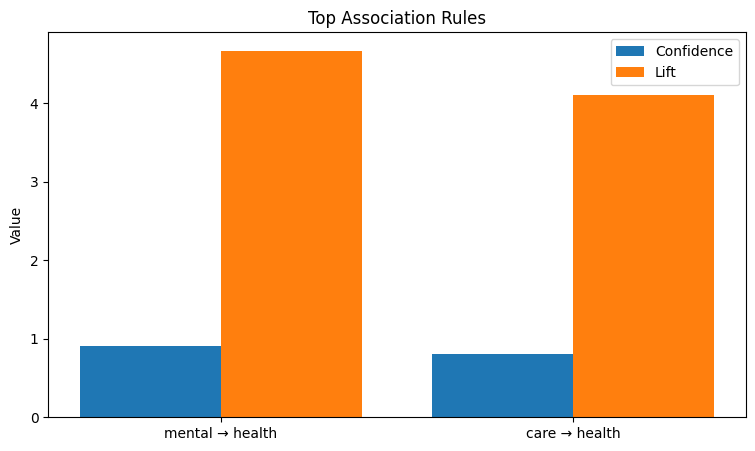

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [56]:
import matplotlib.pyplot as plt

rules_chart = pd.DataFrame({
    'Rule': [
        'mental → health',
        'care → health'
    ],
    'Confidence': [
        0.909091,
        0.800000
    ],
    'Lift': [
        4.670846,
        4.110345
    ]
})

x = range(len(rules_chart))

plt.figure(figsize=(9, 5))

plt.bar(
    [i - 0.2 for i in x],
    rules_chart['Confidence'],
    width=0.4,
    label='Confidence'
)

plt.bar(
    [i + 0.2 for i in x],
    rules_chart['Lift'],
    width=0.4,
    label='Lift'
)

plt.xticks(x, rules_chart['Rule'])
plt.ylabel('Value')
plt.title('Top Association Rules')
plt.legend()

plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

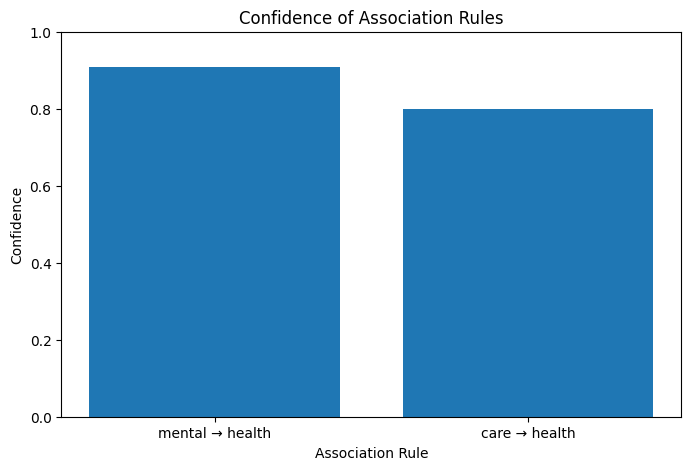

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

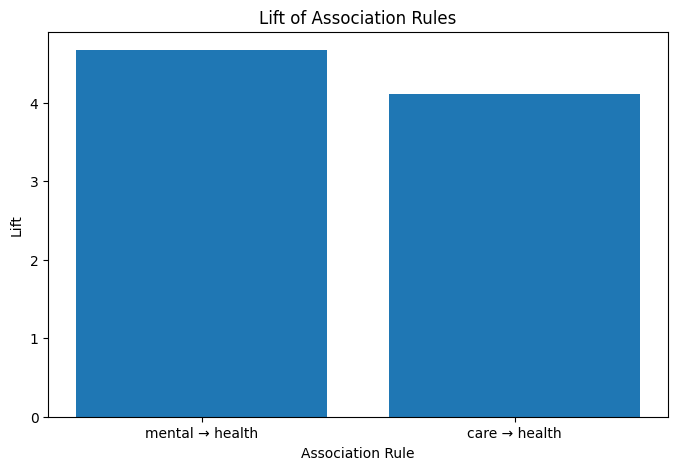

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [57]:
import matplotlib.pyplot as plt

rules_chart = pd.DataFrame({
    'Rule': ['mental → health', 'care → health'],
    'Confidence': [0.909091, 0.800000],
    'Lift': [4.670846, 4.110345]
})

plt.figure(figsize=(8,5))
plt.bar(rules_chart['Rule'], rules_chart['Confidence'])
plt.ylabel('Confidence')
plt.xlabel('Association Rule')
plt.title('Confidence of Association Rules')
plt.ylim(0, 1)
plt.show()

plt.figure(figsize=(8,5))
plt.bar(rules_chart['Rule'], rules_chart['Lift'])
plt.ylabel('Lift')
plt.xlabel('Association Rule')
plt.title('Lift of Association Rules')
plt.show()

In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# -----------------------------
# 1. Word-level TF-IDF
# -----------------------------
word_tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    min_df=1
)

X_train_word = word_tfidf.fit_transform(X_train)
X_test_word = word_tfidf.transform(X_test)

# -----------------------------
# 2. Character-level TF-IDF
# -----------------------------
char_tfidf = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=2
)

X_train_char = char_tfidf.fit_transform(X_train)
X_test_char = char_tfidf.transform(X_test)

print("Word TF-IDF:", X_train_word.shape)
print("Character TF-IDF:", X_train_char.shape)

# -----------------------------
# 3. Combine both features
# -----------------------------
X_train_hybrid = hstack([X_train_word, X_train_char])
X_test_hybrid = hstack([X_test_word, X_test_char])

print("Hybrid features:", X_train_hybrid.shape)

# -----------------------------
# 4. Train SVM
# -----------------------------
hybrid_svm = LinearSVC(random_state=42)

hybrid_svm.fit(X_train_hybrid, y_train)

# -----------------------------
# 5. Prediction
# -----------------------------
y_pred_hybrid = hybrid_svm.predict(X_test_hybrid)

# -----------------------------
# 6. Performance
# -----------------------------
accuracy_hybrid = accuracy_score(y_test, y_pred_hybrid)
precision_hybrid = precision_score(
    y_test, y_pred_hybrid, average='weighted', zero_division=0
)
recall_hybrid = recall_score(
    y_test, y_pred_hybrid, average='weighted', zero_division=0
)
f1_hybrid = f1_score(
    y_test, y_pred_hybrid, average='weighted', zero_division=0
)

print("\n===== HYBRID WORD + CHARACTER TF-IDF SVM =====")
print(f"Accuracy  : {accuracy_hybrid*100:.2f}%")
print(f"Precision : {precision_hybrid*100:.2f}%")
print(f"Recall    : {recall_hybrid*100:.2f}%")
print(f"F1 Score  : {f1_hybrid*100:.2f}%")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Word TF-IDF: (240, 3884)
Character TF-IDF: (240, 6549)
Hybrid features: (240, 10433)

===== HYBRID WORD + CHARACTER TF-IDF SVM =====
Accuracy  : 86.67%
Precision : 87.27%
Recall    : 86.67%
F1 Score  : 86.06%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    'Algorithm': [
        'Naive Bayes',
        'Logistic Regression',
        'SVM',
        'Hybrid TF-IDF + SVM'
    ],
    'Accuracy': [
        68.33,
        80.00,
        85.00,
        86.67
    ],
    'Precision': [
        69.41,
        74.95,
        85.69,
        87.27
    ],
    'F1 Score': [
        60.92,
        75.34,
        84.67,
        86.06
    ]
})

print(comparison)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

             Algorithm  Accuracy  Precision  F1 Score
0          Naive Bayes     68.33      69.41     60.92
1  Logistic Regression     80.00      74.95     75.34
2                  SVM     85.00      85.69     84.67
3  Hybrid TF-IDF + SVM     86.67      87.27     86.06


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

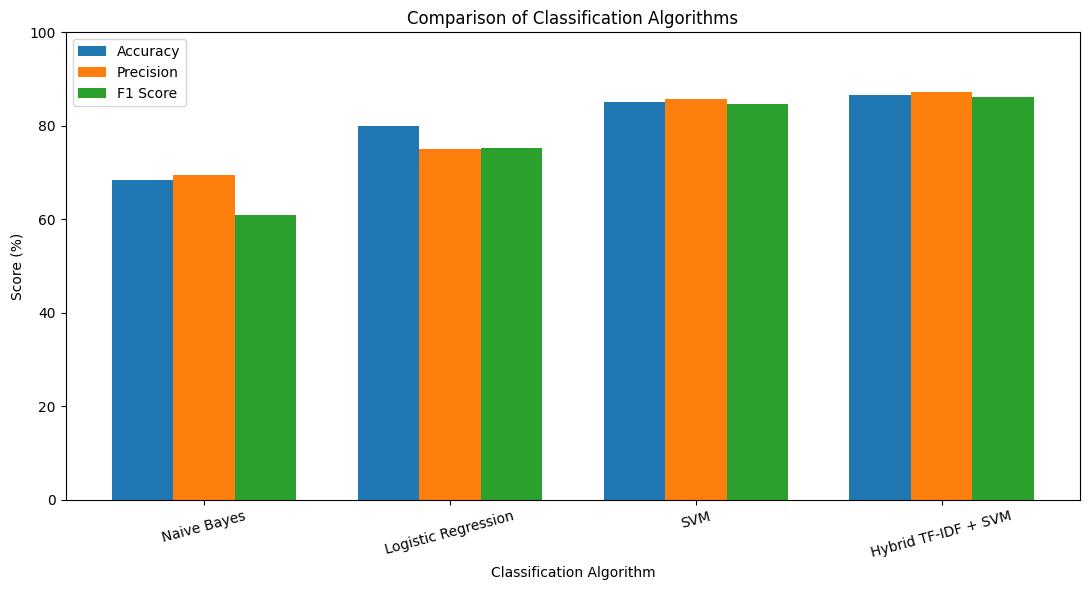

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [60]:
plt.figure(figsize=(11,6))

x = range(len(comparison))
width = 0.25

plt.bar(
    [i - width for i in x],
    comparison['Accuracy'],
    width=width,
    label='Accuracy'
)

plt.bar(
    x,
    comparison['Precision'],
    width=width,
    label='Precision'
)

plt.bar(
    [i + width for i in x],
    comparison['F1 Score'],
    width=width,
    label='F1 Score'
)

plt.xticks(x, comparison['Algorithm'], rotation=15)
plt.ylabel('Score (%)')
plt.xlabel('Classification Algorithm')
plt.title('Comparison of Classification Algorithms')
plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()